<a href="https://colab.research.google.com/github/bachaudhry/my-llm-from-scratch/blob/main/supplementary/pre-training/gpt-to-llama/converting_llama2_to_llama3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Converting Llama 2 to Llama 3

- In this notebook, we will code along with Sebastain's source material which converts Llama 2 to Llama 3 and Llama 3.1 in a step by step fashion.
- In depth details on both models can be found in the following papers:
 - [Llama 2: Open Foundation and Fine-Tuned Chat Models (2023)](https://arxiv.org/abs/2307.09288)
 - [The Llama 3 Herd of Models](https://arxiv.org/abs/2407.21783)

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/bonus/gpt-to-llama/gpt2-to-llama2-llama3.webp?1">

In [ ]:
from importlib.metadata import version
pkgs = [
    "blobfile",         # to download pretrained weights
    "huggingface_hub",
    "matplotlib",
    "tiktoken",
    "torch",
]
for p in pkgs:
    print(f"{p} version: {version(p)}")

blobfile version: 3.3.0
huggingface_hub version: 1.33.0
matplotlib version: 3.10.0
tiktoken version: 0.14.0
torch version: 2.14.1+cu130


# **1. Llama Model Conversion**

- The notebook [converting_gpt_to_llama2](https://github.com/bachaudhry/my-llm-from-scratch/blob/main/supplementary/pre-training/gpt-to-llama/converting_gpt_to_llama2.ipynb), recreated the implementation of Llama 2's components i.e. RMSNorm layers, SilU and SwiGLU activations, RoPE and SentencePiece tokenizer.
- Moving to the conversion of Llama 2 to Llama 3, we will specifically look at:
    - Modifications to the rotary embeddings
    - Implementing GQA.
    - Using a customized version of the GPT-4 tokenizer.

## **1.1 Reusing Llama 2 Components**

- Both Llama 2 and Llama 3 have lots of similarities so most of the building blocks can be imported from the notebook which dealt with the conversion of GPT 2 to Llama 2.

In [ ]:
!git clone https://github.com/bachaudhry/my-llm-from-scratch.git

Cloning into 'my-llm-from-scratch'...
remote: Enumerating objects: 950, done.
remote: Counting objects: 100% (341/341), done.
remote: Compressing objects: 100% (300/300), done.
remote: Total 950 (delta 103), reused 70 (delta 24), pack-reused 609 (from 1)
Receiving objects: 100% (950/950), 2.14 MiB | 9.57 MiB/s, done.
Resolving deltas: 100% (484/484), done.


In [ ]:
import os, sys, io, nbformat, types, ast

repo_folder = 'my-llm-from-scratch/supplementary/pre-training/gpt-to-llama'
os.chdir(repo_folder)
sys.path.append('.') # Add current directory of the repo to the path


- The `import_from_notebook()` function has been rewritten so that it can be used in colab. We need to ensure that:
    - The source repo `my-llm-from-scratch` has been cloned into the colab runtime.
    - The target folder `gpt-to-llama` has been appended to the system path.

In [ ]:
import os
import sys
import io
import nbformat
import types
import ast
import torch
import torch.nn as nn

def import_from_notebook():
    """
    Dynamically imports specific function and class definitions from a Jupyter Notebook.
    It uses AST parsing to safely extract targeted definitions without executing
    unwanted code from the notebook's cells, and injects 'torch' and 'torch.nn as nn'
    into the execution namespace.
    """
    def import_definitions_from_notebook(fullname, names):
        current_dir = os.getcwd()
        path = os.path.join(current_dir, fullname + ".ipynb")
        path = os.path.normpath(path)

        # Load the notebook
        if not os.path.exists(path):
            raise FileNotFoundError(f"Notebook file not found at: {path}")

        with io.open(path, "r", encoding="utf-8") as f:
            nb = nbformat.read(f, as_version=4)

        # Create a module to store the imported functions and classes
        mod = types.ModuleType(fullname)
        sys.modules[fullname] = mod
        mod_dict = mod.__dict__

        # Inject necessary dependencies that were skipped by the AST parser
        mod_dict['torch'] = torch
        mod_dict['nn'] = nn

        # Go through the notebook cells and safely extract definitions using AST
        for cell in nb.cells:
            if cell.cell_type == "code":
                cell_code = cell.source
                try:
                    # Parse the cell code into an Abstract Syntax Tree
                    tree = ast.parse(cell_code)
                    for node in tree.body:
                        # Check if the node is a function or class definition
                        if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
                            if node.name in names:
                                # Wrap the single definition in a module to compile it
                                module_ast = ast.Module(body=[node], type_ignores=[])
                                code_obj = compile(module_ast, filename=f"<notebook_{fullname}>", mode="exec")
                                # Execute ONLY the definition code
                                exec(code_obj, mod_dict)
                except SyntaxError:
                    # Skip cells with syntax errors
                    continue
        return mod

    fullname = "converting_gpt_to_llama2"
    names = ["precompute_rope_params", "compute_rope", "SiLU", "FeedForward", "RMSNorm", "MultiHeadAttention"]

    return import_definitions_from_notebook(fullname, names)


In [ ]:
imported_module = import_from_notebook()

# We need to redefine precompute_rope_params
# precompute_rope_params = getattr(imported_module, "precompute_rope_params", None)
compute_rope = getattr(imported_module, "compute_rope", None)
SiLU = getattr(imported_module, "SiLU", None)
FeedForward = getattr(imported_module, "FeedForward", None)
RMSNorm = getattr(imported_module, "RMSNorm", None)

# MultiHeadAttention only for comparison purposes
MultiHeadAttention = getattr(imported_module, "MultiHeadAttention", None)

In [ ]:
# Print the non-dunder attributes of the imported module to verify extraction
print([attr for attr in dir(imported_module) if not attr.startswith('__')])

['FeedForward', 'MultiHeadAttention', 'RMSNorm', 'SiLU', 'compute_rope', 'nn', 'precompute_rope_params', 'torch']


## **1.2 Modified RoPE**

- Llama 3 uses rotary position embeddings (RoPE) which is similar to Llama 2.
- The original [RoPE paper](https://arxiv.org/abs/2104.09864) contains all the necessary details.
- The subtle differences in RoPE settings, are as follows:
 - Llama 3 now supports up to 8,192 tokens, twice as many as Llama 2 (4,096)
 - The base value for the so-called RoPE $\theta$ (see equation below) was increased from 10,000 (Llama 2) to 500,000 (Llama 3) in the following equation:

$$\Theta = \left\{\theta_i = \text{base}^{\frac{-2(i-1)}{d}}, i \in \left[1, 2, ..., d/2\right]\right\}$$

- These $\theta$ values are a set of predefined parameters that are used to determine the rotational angles in the rotary matrix, where $d$ is the dimensionality of the embedding space
- Increasing the base from 10,000 to 500,000 makes the frequencies decay faster across the dimensions, which means that the higher-dimensional components are associated with smaller rotation angles than before, so the overall frequency range becomes more compressed rather than expanded.
- The change in decay rate supports improved context lengths without increasing the "strength" of the rotations at higher dimensions.

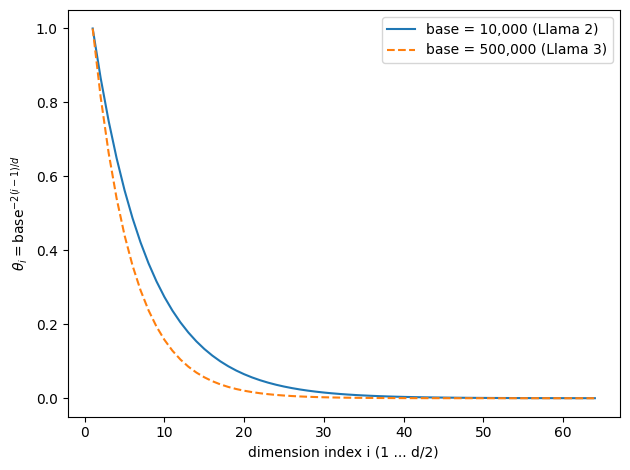

In [ ]:
import matplotlib.pyplot as plt

d = 128
i = torch.arange(1, d // 2 + 1)

base_llama2 = 10_000
base_llama3 = 500_000

theta_llama2 = base_llama2 ** (-2 * (i - 1) / d)
theta_llama3 = base_llama3 ** (-2 * (i - 1) / d)

plt.plot(i, theta_llama2, label="base = 10,000 (Llama 2)")
plt.plot(i, theta_llama3, label="base = 500,000 (Llama 3)", ls="--")
plt.xlabel("dimension index i (1 ... d/2)")
plt.ylabel(r"$\theta_i = \mathrm{base}^{-2(i-1)/d}$")
plt.legend()
plt.tight_layout();


- We will  also introduce a `freq_config` section in the code below that adjusts the frequency; however, it won't be needed in Llama 3 (only Llama 3.1 and Llama 3.2), so this will be set to `None` so that it is ignored by default.

In [ ]:
def precompute_rope_params(head_dim, theta_base=10_000, context_length=4096, freq_config=None):
    assert head_dim % 2 == 0, "Embedding dimension must be even"

    # Compute the inverse frequencies
    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2)[: (head_dim // 2)].float() / head_dim))

    ##################### Modification to the original function #############################
    if freq_config is not None:
        # Frequency adjustments
        low_freq_wavelen = freq_config["original_context_length"] / freq_config["low_freq_factor"]
        high_freq_wavelen = freq_config["original_context_length"] / freq_config["high_freq_factor"]

        wavelen = 2 * torch.pi / inv_freq

        inv_freq_llama = torch.where(
            wavelen > low_freq_wavelen, inv_freq / freq_config["factor"], inv_freq
        )

        smooth_factor = (freq_config["original_context_length"] / wavelen - freq_config["low_freq_factor"]) / (
            freq_config["high_freq_factor"] - freq_config["low_freq_factor"]
        )

        smoothed_inv_freq = (
            (1 - smooth_factor) * (inv_freq / freq_config["factor"]) + smooth_factor * inv_freq
        )

        is_medium_freq = (wavelen <= low_freq_wavelen) & (wavelen >= high_freq_wavelen)
        inv_freq_llama = torch.where(is_medium_freq, smoothed_inv_freq, inv_freq_llama)
        inv_freq = inv_freq_llama

    # Generate position indices
    positions = torch.arange(context_length)

    # Compute angles
    angles = positions.unsqueeze(1) * inv_freq.unsqueeze(0) # Shape: (context_length, head_dim // 2)

    # Expand angles to match the head_dim
    angles = torch.cat([angles, angles], dim=1) # Shape : (context_length, head_dim)

    # Precompute sine and cosine
    cos = torch.cos(angles)
    sin = torch.sin(angles)

    return cos, sin

In [ ]:
# Updating the context length and the theta base parameters for Llama 3

llama_2_context_length = 4096
llama_3_context_length = 8192

llama_2_theta_base = 10_000
llama_3_theta_base = 500_000

In [ ]:
# Settings
batch_size = 2
num_heads = 4
head_dim = 16

# Instantiate RoPE params
cos, sin = precompute_rope_params(
    head_dim=head_dim,
    theta_base=llama_3_theta_base,
    context_length=llama_3_context_length
)

# Dummy query and key tensors
torch.manual_seed(123)
queries = torch.randn(batch_size, num_heads, llama_3_context_length, head_dim)
keys = torch.randn(batch_size, num_heads, llama_3_context_length, head_dim)

# Apply rotary position embeddings
queries_rot = compute_rope(queries, cos, sin)
keys_rot = compute_rope(keys, cos, sin)

## **1.3 Grouped-Query Attention**

- Grouped Query Attention (GQA) and it's inner workings have already been covered in the [architecture_optimizations section](https://github.com/bachaudhry/my-llm-from-scratch/tree/main/supplementary/architecture_optimizations/gqa) of this repo.
- In summary, GQA reduces the number of unique query groups that attend to the key-value pairs, thus reducing the size of some of the matrix multiplications and the number of parameters in MHA without significantly reducing modeling performance.
- The primary change in GQA is that each query group needs to be repeated to match the number of heads it is associated with.
- The attention class is altered so that it receives the mask through its forward method instead of storing and accessing it as `self.mask`.
- Llama 3.1 can handle sequences of up to 128k tokens and precomputing a 128k x 128k causal mask would be extremely memory intensive, so avoid until absolutely necessary.

In [ ]:
class GroupedQueryAttention(nn.Module):
    def __init__(self, d_in, d_out, num_heads, num_kv_groups, dtype=None):
        super().__init__()
        assert d_out % num_heads == 0, "Number of output channels must be divisible by the number of heads"
        assert num_heads % num_kv_groups == 0, "Number of heads must be divisible by the number of key-value groups" # Modification

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.num_kv_groups = num_kv_groups

        ####################### Modification ######################
        self.W_key = nn.Linear(d_in, num_kv_groups * self.head_dim, bias=False, dtype=dtype)
        self.W_value = nn.Linear(d_in, num_kv_groups * self.head_dim, bias=False, dtype=dtype)
        self.group_size = num_heads // num_kv_groups
        ##########################################################

        self.W_query = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.out_proj = nn.Linear(d_out, d_out, bias=False, dtype=dtype)

    def forward(self, x, mask=None, cos=None, sin=None):
        ################### Modification ##################
        # The forward method now accepts `mask` instead of accessing it via self.mask
        # Plus, cos and sin are used as input for RoPE
        ##################################################
        b, num_tokens, d_in = x.shape

        queries = self.W_query(x)  # Shape: (b, num_tokens, d_out)
        keys = self.W_key(x)  # Shape: (b, num_tokens, num_kv_groups * head_dim)
        values = self.W_value(x)  # Shape: (b, num_tokens, num_kv_groups * head_dim)

        # Reshape queries, keys and values
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        ################### Modifications ###################
        keys = keys.view(b, num_tokens, self.num_kv_groups, self.head_dim)
        values = values.view(b, num_tokens, self.num_kv_groups, self.head_dim)

        # Transpose keys, values and queries
        keys = keys.transpose(1, 2) # Shape: (b, num_kv_groups, num_tokens, head_dim)
        values = values.transpose(1, 2) # Shape: (b, num_kv_groups, num_tokens, head_dim)
        queries = queries.transpose(1, 2) # Shape: (b, num_heads, num_tokens, head_dim)

        ################### Modifications ###################
        # Apply RoPE
        if cos is not None:
            keys = compute_rope(keys, cos, sin)
            queries = compute_rope(queries, cos, sin)

        ################### Modifications ###################
        keys = keys.repeat_interleave(self.group_size, dim=1) # Shape (n, num_heads, num_tokens, head_dim)
        values = values.repeat_interleave(self.group_size, dim=1) # Shape (b, num_heads, num_tokens, head_dim)
        ####################################################

        # Compute scaled dot product attention with a causal mask
        # Shape (b, num_heads, num_tokens, num_tokens)
        attn_scores = queries @ keys.transpose(2, 3) # Dot product for each head

        ################### Modifications ###################
        # Create mask on the fly
        if mask is None:
            mask = torch.triu(torch.ones(num_tokens, num_tokens, device=x.device, dtype=torch.bool), diagonal=1)
        #####################################################

        # Use mask to fill attention scores
        attn_scores.masked_fill_(mask, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1] ** 0.5, dim=-1)
        assert keys.shape[-1] == self.head_dim

        # Shape (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.reshape(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec) # Optional projection.

        return context_vec


In [ ]:
# Demonstrating param savings in GQA over MHA
batch_size = 1
context_len = 3000
max_context_length = 8192
embed_dim = 4096
num_heads = 32

example_batch = torch.randn((batch_size, context_len, embed_dim))

mha = MultiHeadAttention(
    d_in=embed_dim,
    d_out=embed_dim,
    context_length=max_context_length,
    num_heads=num_heads
)

mha(example_batch)

print("W_key:", mha.W_key.weight.shape)
print("W_value:", mha.W_value.weight.shape)
print("W_query:", mha.W_query.weight.shape)

W_key: torch.Size([4096, 4096])
W_value: torch.Size([4096, 4096])
W_query: torch.Size([4096, 4096])


In [ ]:
gqa = GroupedQueryAttention(
    d_in=embed_dim,
    d_out=embed_dim,
    num_heads=num_heads,
    num_kv_groups=8,
)

gqa(example_batch)

print("W_key:", gqa.W_key.weight.shape)
print("W_value:", gqa.W_value.weight.shape)
print("W_query:", gqa.W_query.weight.shape)

W_key: torch.Size([1024, 4096])
W_value: torch.Size([1024, 4096])
W_query: torch.Size([4096, 4096])


In [ ]:
print("Total number of parameters:")

mha_total_params = sum(p.numel() for p in mha.parameters())
print(f"MHA: {mha_total_params:,}")

gqa_total_params = sum(p.numel() for p in gqa.parameters())
print(f"GQA: {gqa_total_params:,}")

Total number of parameters:
MHA: 67,108,864
GQA: 41,943,040


In [ ]:
del mha
del gqa

## **1.4 Update The TransformerBlock Module**

- We will update the `TransformerBlock` by swapping `MultiHeadAttention` with `GroupedQueryAttention` with additional RoPE settings.
- The `forward` method also needs updates to handle `mask`, `cos` and `sin`. These values, once computed, remain the same for reuse in each transformer block.

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = GroupedQueryAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            num_heads=cfg["n_heads"],
            num_kv_groups=cfg["n_kv_groups"],
            dtype=cfg["dtype"],
        )
        self.ff = FeedForward(cfg)
        self.norm1 = RMSNorm(cfg["emb_dim"], eps=1e-5)
        self.norm2 = RMSNorm(cfg["emb_dim"], eps=1e-5)

    def forward(self, x, mask=None, cos=None, sin=None):
        # The forward method now accepts `mask` instead of accessing self.mask
        # Additionally, we now have cos and sin as inputs for RoPE

        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x.to(torch.bfloat16), mask, cos, sin) # Shape [batch_size, num_tokens, emb_size]
        x = x + shortcut # Add the original input back

        # Shortcut connection for feed-forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x.to(torch.bfloat16))
        x = x + shortcut # Add the original input back

        return x

## **1.5 Define the Model Class**

- The `Llama3Model` class remains largely the same, except for the addition of `mask`, `cos` and `sin` in the transformer blocks.

In [ ]:
class Llama3Model(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"], dtype=cfg["dtype"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )
        self.final_norm = RMSNorm(cfg["emb_dim"], eps=1e-5)
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False, dtype=cfg["dtype"])

        ############## Modification ################
        cos, sin = precompute_rope_params(
            head_dim=cfg["emb_dim"] // cfg["n_heads"],
            theta_base=cfg["theta_base"],
            context_length=cfg["max_context_length"],
            freq_config=cfg["rope_freq"]
        )

        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

        self.cfg = cfg

    def forward(self, in_idx):
        tok_embeds = self.tok_emb(in_idx)
        x = tok_embeds

        ################ Modification ################
        num_tokens = x.shape[1]
        mask = torch.triu(torch.ones(num_tokens, num_tokens, device=x.device, dtype=torch.bool), diagonal=1)

        for block in self.trf_blocks:
            x = block(x, mask, self.cos, self.sin)
        x = self.final_norm(x)
        logits = self.out_head(x.to(self.cfg["dtype"]))
        return logits

# **2. Initialize The Model**

In [ ]:
LLAMA2_CONFIG_7B = {
    "vocab_size": 32_000,    # Vocabulary size
    "context_length": 4096,  # Context length
    "emb_dim": 4096,         # Embedding dimension
    "n_heads": 32,           # Number of attention heads
    "n_layers": 32,          # Number of layers
    "hidden_dim": 11_008,    # Size of the intermediate dimension in FeedForward
    "dtype": torch.bfloat16  # Lower-precision dtype to reduce memory usage
}

In [ ]:
LLAMA3_CONFIG_8B = {
    "vocab_size": 128_256,   # NEW: Larger vocabulary size
    "context_length": 8192,  # NEW: Larger context length
    "emb_dim": 4096,         # Embedding dimension
    "n_heads": 32,           # Number of attention heads
    "n_layers": 32,          # Number of layers
    "hidden_dim": 14_336,    # NEW: Larger size of the intermediate dimension in FeedForward
    "n_kv_groups": 8,        # NEW: Key-Value groups for grouped-query attention
    "rope_base": 500_000.0,  # NEW: The base in RoPE's "theta" was increased to 500_000
    "rope_freq": None,       # NEW: Additional configuration for adjusting the RoPE frequencies
    "dtype": torch.bfloat16  # Lower-precision dtype to reduce memory usage
}

In [ ]:
model = Llama3Model(LLAMA3_CONFIG_8B)

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

NameError: name 'model' is not defined

In [ ]:
def calc_model_memory_size(model, input_dtype=torch.float32):
    total_params = 0
    total_grads = 0
    for param in model.parameters():
        # Calculate total number of elements per parameter
        param_size = param.numel()
        total_params += param_size
        # Check if gradients are stored for this parameter
        if param.requires_grad:
            total_grads += param_size

    # Calculate buffer size (non-parameters that require memory)
    total_buffers = sum(buf.numel() for buf in model.buffers())

    # Size in bytes = (Number of elements) * (Size of each element in bytes)
    # We assume parameters and gradients are stored in the same type as input dtype
    element_size = torch.tensor(0, dtype=input_dtype).element_size()
    total_memory_bytes = (total_params + total_grads + total_buffers) * element_size

    # Convert bytes to gigabytes
    total_memory_gb = total_memory_bytes / (1024**3)

    return total_memory_gb

print(f"float32 (PyTorch default): {calc_model_memory_size(model, input_dtype=torch.float32):.2f} GB")
print(f"bfloat16: {calc_model_memory_size(model, input_dtype=torch.bfloat16):.2f} GB")

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

model.to(device);

# **3. Load Tokenizer**

In [ ]:
from pathlib import Path

import tiktoken
from tiktoken.load import load_tiktoken_bpe


class Tokenizer:
    """Thin wrapper around tiktoken that keeps track of Llama-3 special IDs."""
    def __init__(self, model_path):
        if not os.path.isfile(model_path):
            raise FileNotFoundError(model_path)

        mergeable = load_tiktoken_bpe(model_path)

        # hard-coded from Meta's tokenizer.json
        self.special = {
            "<|begin_of_text|>": 128000,
            "<|end_of_text|>": 128001,
            "<|start_header_id|>": 128006,
            "<|end_header_id|>": 128007,
            "<|eot_id|>": 128009,
        }
        self.special.update({f"<|reserved_{i}|>": 128002 + i
                             for i in range(256)
                             if 128002 + i not in self.special.values()})

        self.model = tiktoken.Encoding(
            name=Path(model_path).name,
            pat_str=r"(?i:'s|'t|'re|'ve|'m|'ll|'d)"
                    r"|[^\r\n\p{L}\p{N}]?\p{L}+"
                    r"|\p{N}{1,3}"
                    r"| ?[^\s\p{L}\p{N}]+[\r\n]*"
                    r"|\s*[\r\n]+"
                    r"|\s+(?!\S)"
                    r"|\s+",
            mergeable_ranks=mergeable,
            special_tokens=self.special,
        )

    def encode(self, text, bos=False, eos=False):
        ids = ([self.special["<|begin_of_text|>"]] if bos else []) \
              + self.model.encode(text)
        if eos:
            ids.append(self.special["<|end_of_text|>"])
        return ids

    def decode(self, ids):
        return self.model.decode(ids)

In [ ]:
from huggingface_hub import login
import json

with open("config.json", "r") as config_file:
    config = json.load(config_file)
    access_token = config["HF_ACCESS_TOKEN"]

login(token=access_token)

In [ ]:
from huggingface_hub import hf_hub_download

tokenizer_file_path = hf_hub_download(
    repo_id="meta-llama/Meta-Llama-3-8B",
    filename="original/tokenizer.model",
    local_dir="Llama-3-8B"
)

In [ ]:
tokenizer = Tokenizer(tokenizer_file_path)

In [ ]:
from llms_from_scratch.ch05 import generate, text_to_token_ids, token_ids_to_text


torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort", tokenizer).to(device),
    max_new_tokens=30,
    context_size=LLAMA3_CONFIG_8B["context_length"],
    top_k=1,
    temperature=0.
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

# **4. Load Pre-Trained Weights**

In [ ]:
from safetensors.torch import load_file

combined_weights = {}

for i in range(1, 5):
    weights_file = hf_hub_download(
        repo_id="meta-llama/Meta-Llama-3-8B",
        filename=f"model-0000{i}-of-00004.safetensors",
        local_dir="Llama-3-8B"
    )
    current_weights = load_file(weights_file)
    combined_weights.update(current_weights)

In [ ]:
list(combined_weights.keys())[:15]

In [ ]:
def assign(left, right, tensor_name="unknown"):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch in tensor '{tensor_name}'. Left: {left.shape}, Right: {right.shape}")

    with torch.no_grad():
        if isinstance(right, torch.Tensor):
            left.copy_(right)
        else:
            left.copy_(torch.as_tensor(right, dtype=left.dtype, device=left.device))

    return left


def load_weights_into_llama(model, param_config, params):
    model.tok_emb.weight = assign(model.tok_emb.weight, params["model.embed_tokens.weight"], "model.embed_tokens.weight")

    for l in range(param_config["n_layers"]):

        # Load attention weights
        model.trf_blocks[l].att.W_query.weight = assign(
            model.trf_blocks[l].att.W_query.weight,
            params[f"model.layers.{l}.self_attn.q_proj.weight"],
            f"model.layers.{l}.self_attn.q_proj.weight"
        )
        model.trf_blocks[l].att.W_key.weight = assign(
            model.trf_blocks[l].att.W_key.weight,
            params[f"model.layers.{l}.self_attn.k_proj.weight"],
            f"model.layers.{l}.self_attn.k_proj.weight"
        )
        model.trf_blocks[l].att.W_value.weight = assign(
            model.trf_blocks[l].att.W_value.weight,
            params[f"model.layers.{l}.self_attn.v_proj.weight"],
            f"model.layers.{l}.self_attn.v_proj.weight"
        )
        model.trf_blocks[l].att.out_proj.weight = assign(
            model.trf_blocks[l].att.out_proj.weight,
            params[f"model.layers.{l}.self_attn.o_proj.weight"],
            f"model.layers.{l}.self_attn.o_proj.weight"
        )
        model.trf_blocks[l].norm1.weight = assign(
            model.trf_blocks[l].norm1.weight,
            params[f"model.layers.{l}.input_layernorm.weight"],
            f"model.layers.{l}.input_layernorm.weight"
        )

        # Load FeedForward weights
        model.trf_blocks[l].ff.fc1.weight = assign(
            model.trf_blocks[l].ff.fc1.weight,
            params[f"model.layers.{l}.mlp.gate_proj.weight"],
            f"model.layers.{l}.mlp.gate_proj.weight"
        )
        model.trf_blocks[l].ff.fc2.weight = assign(
            model.trf_blocks[l].ff.fc2.weight,
            params[f"model.layers.{l}.mlp.up_proj.weight"],
            f"model.layers.{l}.mlp.up_proj.weight"
        )
        model.trf_blocks[l].ff.fc3.weight = assign(
            model.trf_blocks[l].ff.fc3.weight,
            params[f"model.layers.{l}.mlp.down_proj.weight"],
            f"model.layers.{l}.mlp.down_proj.weight"
        )
        model.trf_blocks[l].norm2.weight = assign(
            model.trf_blocks[l].norm2.weight,
            params[f"model.layers.{l}.post_attention_layernorm.weight"],
            f"model.layers.{l}.post_attention_layernorm.weight"
        )

    # Load output layer weights
    model.final_norm.weight = assign(model.final_norm.weight, params["model.norm.weight"], "model.norm.weight")

    if "lm_head.weight" in params.keys():
        model.out_head.weight = assign(model.out_head.weight, params["lm_head.weight"], "lm_head.weight")
    else:
        model.out_head.weight = model.tok_emb.weight
        print("Model uses weight tying.")


load_weights_into_llama(model, LLAMA3_CONFIG_8B, combined_weights)
model.to(device);
del combined_weights  # free up memory

In [ ]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort", tokenizer).to(device),
    max_new_tokens=25,
    context_size=LLAMA3_CONFIG_8B["context_length"],
    top_k=1,
    temperature=0.
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

# **5. Instruction Fine-Tuned Model**

In [ ]:
# to free up memory

import gc

del model

gc.collect()  # Run Python garbage collector

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [ ]:
combined_weights = {}

for i in range(1, 5):
    weights_file = hf_hub_download(
        repo_id="meta-llama/Meta-Llama-3-8B-Instruct",
        filename=f"model-0000{i}-of-00004.safetensors",
        local_dir="Llama-3-8B-Instruct"
    )
    current_weights = load_file(weights_file)
    combined_weights.update(current_weights)


model = Llama3Model(LLAMA3_CONFIG_8B)
load_weights_into_llama(model, LLAMA3_CONFIG_8B, combined_weights)
model.to(device)
del combined_weights  # free up memory

In [ ]:
class ChatFormat:

    def __init__(self, tokenizer: Tokenizer, *,
                 default_system="You are a helpful assistant."):
        self.tok = tokenizer
        self.default_system = default_system

    def _header(self, role):
        """Encode <|start_header_id|>role<|end_header_id|>\n\n"""
        return (
            [self.tok.special["<|start_header_id|>"]]
            + self.tok.encode(role)
            + [self.tok.special["<|end_header_id|>"]]
            + self.tok.encode("\n\n")
        )

    def encode(self, user_message, system_message=None):
        sys_msg = system_message if system_message is not None else self.default_system

        ids = [self.tok.special["<|begin_of_text|>"]]

        # system
        ids += self._header("system")
        ids += self.tok.encode(sys_msg)
        ids += [self.tok.special["<|eot_id|>"]]

        # user
        ids += self._header("user")
        ids += self.tok.encode(user_message)
        ids += [self.tok.special["<|eot_id|>"]]

        # assistant header (no content yet)
        ids += self._header("assistant")

        return ids

In [ ]:
tokenizer = Tokenizer(tokenizer_file_path)
chat_tokenizer = ChatFormat(tokenizer)

token_ids = chat_tokenizer.encode("Hello World!")
print(token_ids)

In [ ]:
tokenizer.decode(token_ids)torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("What is the difference between a circle and elipse?", chat_tokenizer).to(device),
    max_new_tokens=150,
    context_size=LLAMA3_CONFIG_8B["context_length"],
    top_k=1,
    temperature=0.
)

output_text = token_ids_to_text(token_ids, tokenizer)


def clean_text(text, header_end="assistant<|end_header_id|>\n\n"):
    # Find the index of the first occurrence of "<|end_header_id|>"
    index = text.find(header_end)

    if index != -1:
        # Return the substring starting after "<|end_header_id|>"
        return text[index + len(header_end):].strip()  # Strip removes leading/trailing whitespace
    else:
        # If the token is not found, return the original text
        return text

print("Output text:\n", clean_text(output_text))

##